In [4]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import pandas as pd

In [6]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from src.utils import *
set_plot_style()
print("setup ok")

setup ok


In [7]:
raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=POLLUTANTS + ["AQI"])
df["Month"] = df["Date"].dt.month
df["Season"] = df["Month"].map(season_of)
df["Poor_Flag"] = df["AQI"].map(poor_flag)
print(df.shape)
print(df["Poor_Flag"].value_counts(normalize=True).round(3))

(1698, 19)
Poor_Flag
1    0.723
0    0.277
Name: proportion, dtype: float64


In [8]:
season_d = pd.get_dummies(df["Season"]).drop(columns="Winter").astype(float)
X = pd.concat([df[POLLUTANTS], season_d], axis=1)
y = df["Poor_Flag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE,
                                          random_state=SEED, stratify=y)

logit = sm.Logit(y_tr, sm.add_constant(X_tr)).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:              Poor_Flag   No. Observations:                 1358
Model:                          Logit   Df Residuals:                     1345
Method:                           MLE   Df Model:                           12
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.7418
Time:                        10:05:31   Log-Likelihood:                -207.13
converged:                       True   LL-Null:                       -802.15
Covariance Type:            nonrobust   LLR p-value:                2.408e-247
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -11.7529      1.198     -9.812      0.000     -14.101      -9.405
PM2.5            0.0526      0.010      5.386      0.000       0.033       0.072
PM10             0.0280      0.003      8.46

In [9]:
p_te = logit.predict(sm.add_constant(X_te))
pred_te = (p_te >= 0.5).astype(int)
print(pd.DataFrame(confusion_matrix(y_te, pred_te),
                   index=["Actual not Poor", "Actual Poor"],
                   columns=["Pred not Poor", "Pred Poor"]))
m = classification_metrics(y_te, pred_te, p_te)
m["Gini"] = 2 * m["ROC_AUC"] - 1
print({k: round(v, 3) for k, v in m.items()})

                 Pred not Poor  Pred Poor
Actual not Poor             76         18
Actual Poor                 13        233
{'Accuracy': 0.909, 'Precision': 0.928, 'Recall': 0.947, 'F1': 0.938, 'ROC_AUC': 0.961, 'Gini': 0.921}


In [10]:
print(f"Share of Poor days in test set: {y_te.mean():.3f}")

Share of Poor days in test set: 0.724


In [11]:
def hosmer_lemeshow(y_true, p_hat, g=10):
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(p_hat)})
    d["bin"] = pd.qcut(d["p"], g, duplicates="drop")
    t = d.groupby("bin", observed=True).agg(n=("y", "size"), obs=("y", "sum"), exp=("p", "sum"))
    t["obs0"], t["exp0"] = t["n"] - t["obs"], t["n"] - t["exp"]
    eps = 1e-9
    stat = (((t["obs"] - t["exp"]) ** 2 / (t["exp"] + eps)) +
            ((t["obs0"] - t["exp0"]) ** 2 / (t["exp0"] + eps))).sum()
    dof = len(t) - 2
    return stat, dof, 1 - stats.chi2.cdf(stat, dof), t

hl_stat, hl_dof, hl_p, hl_table = hosmer_lemeshow(y_tr, logit.predict(sm.add_constant(X_tr)))
print(f"Hosmer-Lemeshow: chi2 = {hl_stat:.2f}, df = {hl_dof}, p = {hl_p:.3f}")
hl_table.round(2)

Hosmer-Lemeshow: chi2 = 15.30, df = 8, p = 0.053


,n,obs,exp,obs0,exp0
bin,,,,,
"(5.6607579e-05, 0.015056907]",136,0,0.58,136,135.42
"(0.015056907, 0.15325283]",136,11,8.90,125,127.10
"(0.15325283, 0.63893184]",136,49,53.35,87,82.65
"(0.63893184, 0.91359865]",135,110,108.66,25,26.34
"(0.91359865, 0.98938824]",136,135,131.13,1,4.87
"(0.98938824, 0.99908856]",136,133,135.43,3,0.57
"(0.99908856, 0.99993677]",135,135,134.96,0,0.04
"(0.99993677, 0.99999784]",136,136,136.00,0,0.00
"(0.99999784, 0.99999998]",136,136,136.00,0,0.00


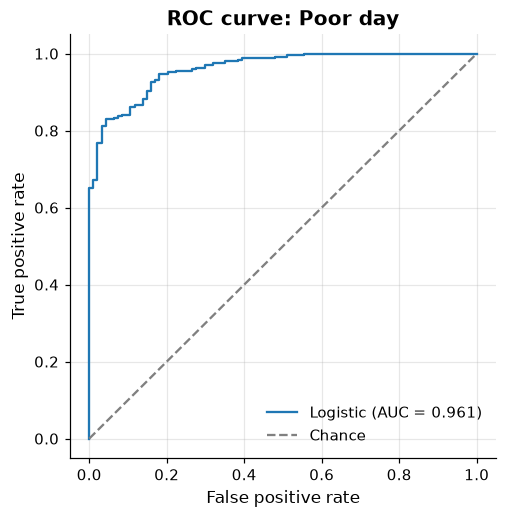

In [12]:
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"Logistic (AUC = {roc_auc_score(y_te, p_te):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Chance")
ax.set(title="ROC curve: Poor day", xlabel="False positive rate", ylabel="True positive rate")
ax.legend()
plt.show()

In [13]:
orr = np.exp(pd.concat([logit.params, logit.conf_int()], axis=1))
orr.columns = ["Odds ratio", "2.5%", "97.5%"]
orr.drop("const").round(3)

,Odds ratio,2.5%,97.5%
PM2.5,1.054,1.034,1.074
PM10,1.028,1.022,1.035
NO,0.992,0.964,1.020
NO2,0.973,0.941,1.006
NOx,1.028,1.017,1.038
NH3,1.028,0.996,1.062
CO,1.920,1.592,2.315
SO2,1.025,0.970,1.083
O3,1.040,1.020,1.060
Monsoon,0.296,0.090,0.971


In [14]:
clf_results = [{"Model": "Logistic regression", **m}]

In [15]:
df["AQI_Group"] = df["AQI"].map(aqi_group)
print(df["AQI_Group"].value_counts())

AQI_Group
High        1227
Moderate     388
Low           83
Name: count, dtype: int64


In [16]:
code = {"Low": 0, "Moderate": 1, "High": 2}
y3 = df["AQI_Group"].map(code)
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X, y3, test_size=TEST_SIZE,
                                              random_state=SEED, stratify=y3)
mnl = sm.MNLogit(y_tr3, sm.add_constant(X_tr3)).fit(method="bfgs", maxiter=2000, disp=0)
print(mnl.summary())

c:\Users\user\Downloads\aqi-predictive-analytics-starter\aqi-predictive-analytics\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3283: RuntimeWarning: overflow encountered in exp
  eXB = np.column_stack((np.ones(len(X)), np.exp(X)))
c:\Users\user\Downloads\aqi-predictive-analytics-starter\aqi-predictive-analytics\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3284: RuntimeWarning: invalid value encountered in divide
  return eXB / eXB.sum(1)[:, None]
c:\Users\user\Downloads\aqi-predictive-analytics-starter\aqi-predictive-analytics\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3315: RuntimeWarning: divide by zero encountered in log
  logprob = np.log(self.cdf(np.dot(self.exog, params)))
c:\Users\user\Downloads\aqi-predictive-analytics-starter\aqi-predictive-analytics\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3316: RuntimeWarning: invalid value encountered in multiply
  return np.sum(d * logprob)
c:\Users\user\Download

ValueError: need covariance of parameters for computing (unnormalized) covariances

In [17]:
print(df["AQI_Group"].value_counts())
print("converged:", mnl.mle_retvals["converged"])
print("largest |coefficient|:", mnl.params.abs().max().max())

AQI_Group
High        1227
Moderate     388
Low           83
Name: count, dtype: int64
converged: False
largest |coefficient|: 791.2924511855412


In [18]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_tr3[POLLUTANTS])

def scale(Xd):
    Z = Xd.copy()
    Z[POLLUTANTS] = sc.transform(Xd[POLLUTANTS])
    return sm.add_constant(Z, has_constant="add")

mnl = sm.MNLogit(y_tr3, scale(X_tr3)).fit(method="newton", maxiter=200, disp=1)
print(mnl.summary())

         Current function value: 0.203514
         Iterations: 200


c:\Users\user\Downloads\aqi-predictive-analytics-starter\aqi-predictive-analytics\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:858: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mnfit = base.LikelihoodModel.fit(


                          MNLogit Regression Results                          
Dep. Variable:              AQI_Group   No. Observations:                 1358
Model:                        MNLogit   Df Residuals:                     1332
Method:                           MLE   Df Model:                           24
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.7176
Time:                        13:04:13   Log-Likelihood:                -276.37
converged:                      False   LL-Null:                       -978.56
Covariance Type:            nonrobust   LLR p-value:                5.783e-282
 AQI_Group=1       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           43.8120   1.28e+04      0.003      0.997    -2.5e+04    2.51e+04
PM2.5            6.8811      4.034      1.706      0.088      -1.026      14.788
PM10             9.6137      2.397      4.01

In [19]:
proba3 = mnl.predict(scale(X_te3))

In [20]:
print(pd.crosstab(df["Season"], df["AQI_Group"]))

AQI_Group     High  Low  Moderate
Season                           
Monsoon        166   80       252
Post-monsoon   279    2        24
Summer         358    1        92
Winter         424    0        20


In [21]:
from sklearn.preprocessing import StandardScaler
Xp_tr, Xp_te = X_tr3[POLLUTANTS], X_te3[POLLUTANTS]
sc = StandardScaler().fit(Xp_tr)

def scale_p(Xd):
    Z = pd.DataFrame(sc.transform(Xd), index=Xd.index, columns=Xd.columns)
    return sm.add_constant(Z)

mnl = sm.MNLogit(y_tr3, scale_p(Xp_tr)).fit(method="newton", maxiter=200, disp=1)
print("converged:", mnl.mle_retvals["converged"])
print(mnl.summary())

Optimization terminated successfully.
         Current function value: 0.206231
         Iterations 13
converged: True
                          MNLogit Regression Results                          
Dep. Variable:              AQI_Group   No. Observations:                 1358
Model:                        MNLogit   Df Residuals:                     1338
Method:                           MLE   Df Model:                           18
Date:                Mon, 12 Oct 2026   Pseudo R-squ.:                  0.7138
Time:                        13:05:59   Log-Likelihood:                -280.06
converged:                       True   LL-Null:                       -978.56
Covariance Type:            nonrobust   LLR p-value:                6.321e-286
AQI_Group=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          24.3410      3.982      6.112      0.000      16.536      32.146
PM2.5    

In [22]:
proba3 = mnl.predict(scale_p(Xp_te))
pred3 = np.asarray(proba3).argmax(axis=1)
print(pd.DataFrame(confusion_matrix(y_te3, pred3),
                   index=["Actual Low", "Actual Moderate", "Actual High"],
                   columns=["Pred Low", "Pred Moderate", "Pred High"]))
m3 = classification_metrics(y_te3, pred3, np.asarray(proba3))
print({k: round(v, 3) for k, v in m3.items()})
clf_results.append({"Model": "Multinomial (3 groups, macro)", **m3})

                 Pred Low  Pred Moderate  Pred High
Actual Low             12              4          0
Actual Moderate         6             60         12
Actual High             1             13        232
{'Accuracy': 0.894, 'Precision': 0.787, 'Recall': 0.821, 'F1': 0.802, 'ROC_AUC': 0.97}


In [23]:
print(mnl.mle_retvals["converged"])

True


In [24]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def fit_tree(Xtr, ytr, scoring):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    grid = {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [5, 10, 20]}
    gs = GridSearchCV(DecisionTreeClassifier(criterion="gini", random_state=SEED),
                      grid, cv=cv, scoring=scoring)
    gs.fit(Xtr, ytr)
    return gs.best_estimator_, gs.best_params_

# Binary: Poor day
tree_b, bp_b = fit_tree(X_tr[POLLUTANTS], y_tr, "roc_auc")
p_tb = tree_b.predict_proba(X_te[POLLUTANTS])[:, 1]
mb = classification_metrics(y_te, tree_b.predict(X_te[POLLUTANTS]), p_tb)
mb["Gini"] = 2 * mb["ROC_AUC"] - 1

# 3-class: AQI group (macro-F1 so the rare Low class counts)
tree_3, bp_3 = fit_tree(Xp_tr, y_tr3, "f1_macro")
m_t3 = classification_metrics(y_te3, tree_3.predict(Xp_te), tree_3.predict_proba(Xp_te))

print("Binary tree settings:", bp_b, {k: round(v, 3) for k, v in mb.items()})
print("3-class tree settings:", bp_3, {k: round(v, 3) for k, v in m_t3.items()})

Binary tree settings: {'max_depth': 6, 'min_samples_leaf': 20} {'Accuracy': 0.903, 'Precision': 0.935, 'Recall': 0.931, 'F1': 0.933, 'ROC_AUC': 0.923, 'Gini': 0.847}
3-class tree settings: {'max_depth': 6, 'min_samples_leaf': 5} {'Accuracy': 0.865, 'Precision': 0.777, 'Recall': 0.813, 'F1': 0.793, 'ROC_AUC': 0.918}


PM2.5    0.736
PM10     0.137
CO       0.060
NO2      0.036
O3       0.029
NO       0.002
NOx      0.000
NH3      0.000
SO2      0.000
dtype: float64


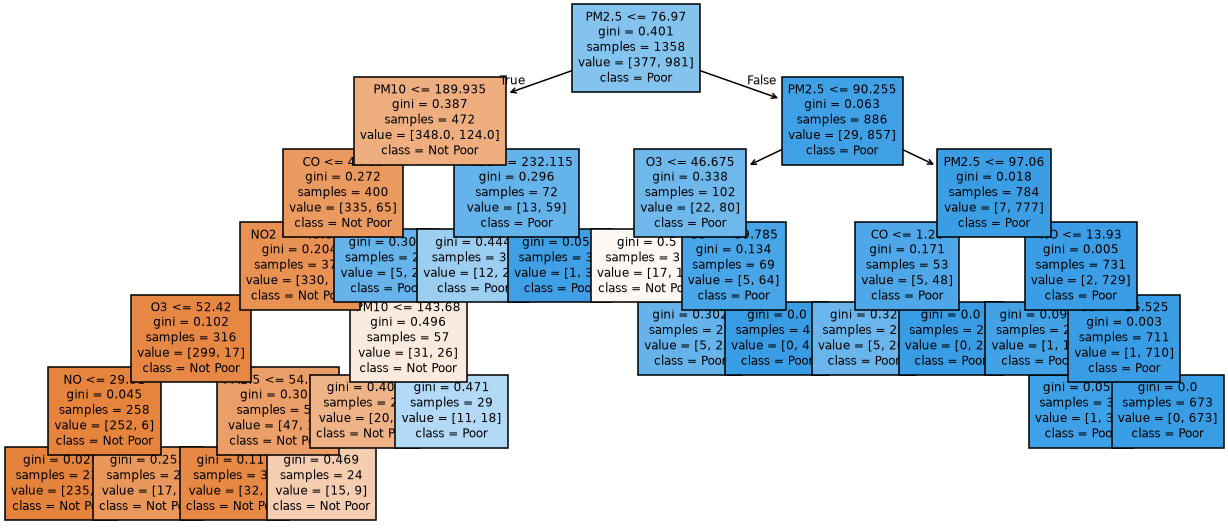

|--- PM2.5 <= 76.97
|   |--- PM10 <= 189.93
|   |   |--- CO <= 4.71
|   |   |   |--- NO2 <= 45.65
|   |   |   |   |--- O3 <= 52.42
|   |   |   |   |   |--- NO <= 29.51
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- NO >  29.51
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- O3 >  52.42
|   |   |   |   |   |--- PM2.5 <= 54.92
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- PM2.5 >  54.92
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- NO2 >  45.65
|   |   |   |   |--- PM10 <= 143.68
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- PM10 >  143.68
|   |   |   |   |   |--- class: 1
|   |   |--- CO >  4.71
|   |   |   |--- class: 1
|   |--- PM10 >  189.93
|   |   |--- PM10 <= 232.11
|   |   |   |--- class: 1
|   |   |--- PM10 >  232.11
|   |   |   |--- class: 1
|--- PM2.5 >  76.97
|   |--- PM2.5 <= 90.26
|   |   |--- O3 <= 46.67
|   |   |   |--- class: 0
|   |   |--- O3 >  46.67
|   |   |   |--- O3 <= 59.79
|   |   |   |   |--- class: 1

In [25]:
imp = pd.Series(tree_b.feature_importances_, index=POLLUTANTS).sort_values(ascending=False)
print(imp.round(3))

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree_b, feature_names=POLLUTANTS, class_names=["Not Poor", "Poor"],
          filled=True, fontsize=8, ax=ax)
plt.show()
print(export_text(tree_b, feature_names=POLLUTANTS))

In [26]:
ct = pd.crosstab(df["Season"], df["AQI_Group"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct)
print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p:.3g}")

AQI_Group     High  Low  Moderate
Season                           
Monsoon        166   80       252
Post-monsoon   279    2        24
Summer         358    1        92
Winter         424    0        20
chi2 = 601.0, df = 6, p = 1.44e-126


In [27]:
from sklearn.metrics import classification_report
print(classification_report(y_te3, pred3, target_names=["Low", "Moderate", "High"]))

              precision    recall  f1-score   support

         Low       0.63      0.75      0.69        16
    Moderate       0.78      0.77      0.77        78
        High       0.95      0.94      0.95       246

    accuracy                           0.89       340
   macro avg       0.79      0.82      0.80       340
weighted avg       0.90      0.89      0.90       340

